# An introduction to pandas

So far we have worked with tables by writing our own loops: a loop to read every row, a loop to count values, a loop to add things up. That's a great way to understand what is happening, but it takes a lot of code, and we keep writing the same patterns over and over.

**pandas** is a Python library made for working with tables. It does the looping for us, so a question that took ten lines of code can often be answered in one. In this notebook we'll use pandas to revisit a question from the Week 7 notes: **where were the Giller nominees born, and where do they live now?**

### Our data

We'll use the file `giller_authors.csv`, which we saved at the end of the Week 7 notes. It is the table we cleaned by hand this week:
- It has **one row per author**, not one row per book. 
- The regions have already been cleaned with our corrections dictionary.
- Unknown values are written as `Unknown`.

Because the cleaning is already done, we can focus on what pandas can do.

## 1. Loading the data

`import pandas as pd` loads the library. This is a convention that most people use to abbrievate pandas, so you will see `pd.` at the start of many pandas commands.

`pd.read_csv()` reads a whole CSV file in one step. Compare this with the `with open(...)` and `csv.DictReader` code we have been writing!

In [32]:
import pandas as pd

authors = pd.read_csv("giller_authors.csv")

print(len(authors), "authors")
type(authors)

218 authors


pandas.core.frame.DataFrame

The variable `authors` has the pandas type `DataFrame`.  You can think of a DataFrame as a table with rows and columns. The big advantage of a specialized type like this is that there are a wide range of methods that operate on the table.  You will also see below that the DataFrame is displayed in a nicer way.

`authors.head()` shows us its first five rows.

In [33]:
authors.head()

,Author,Born,Born region,Born in Canada,Residence,Lives region,Lives in Canada,Nominations
0,Ann-Marie MacDonald,"CFB Baden-Soellingen, West Germany",West Germany,Elsewhere,"Toronto, ON",ON,Canada,2
1,Carol Shields,"Oak Park, IL, USA",USA,Elsewhere,"Victoria, BC",BC,Canada,2
2,Mordecai Richler,"Montreal, QC",QC,Canada,"Montreal, QC",QC,Canada,1
3,Wayne Johnston,"Goulds, NL",NL,Canada,"Toronto, ON",ON,Canada,5
4,David Macfarlane,"Hamilton, ON",ON,Canada,"Toronto, ON",ON,Canada,1


This looks a lot like a spreadsheet:
- The **column names** come from the header row of the CSV file.
- The numbers on the left (0, 1, 2, ...) are the **index**: pandas numbers the rows for us, starting from 0, just like a list.


## 2. Looking at one column

To get one column, we put its name in square brackets. This is just like getting a value from a dictionary, as in `book["Born"]`, except that we get the **whole column**: the value for every author at once.

Notice that pandas only shows the first and last few values of a long column, so the output stays readable.


A single column is called a **Series**.

In [34]:
authors["Born region"]

0      West Germany
1               USA
2                QC
3                NL
4                ON
           ...     
213    South Africa
214              ON
215              ON
216              QC
217              ON
Name: Born region, Length: 218, dtype: object

## 3. Counting

Remember the counting loop we've written so many times?

```python
counts = {}
for author in birthplaces:
    region = ...
    if region in counts:
        counts[region] = counts[region] + 1
    else:
        counts[region] = 1
```

In pandas, that whole loop is one method: `.value_counts()`. It counts how many times each value appears in a column, and sorts the results from most to least common.

In [35]:
authors["Born in Canada"].value_counts()

Born in Canada
Canada       160
Elsewhere     55
Unknown        3
Name: count, dtype: int64

These are the same numbers we found in the Week 7 notes: 160 nominees born in Canada, 55 born elsewhere, and 3 unknown.

Now let's count the regions where the nominees were born:

In [36]:
born_counts = authors["Born region"].value_counts()

born_counts

Born region
ON                     63
BC                     26
QC                     23
AB                     14
NL                     10
USA                    10
England                 9
MB                      8
SK                      7
NS                      5
Unknown                 3
NB                      2
Israel                  2
Hong Kong               2
Trinidad and Tobago     2
West Germany            2
South Africa            2
Nigeria                 2
Ireland                 2
Lebanon                 2
Sri Lanka               2
Tibet                   1
Italy                   1
NU                      1
Northern Ireland        1
Scotland                1
South Vietnam           1
China                   1
Kenya                   1
India                   1
Egypt                   1
Thailand                1
Serbia                  1
Saudi Arabia            1
Germany                 1
Latvia                  1
Yugoslavia              1
Canada                  1


The result of `.value_counts()` is itself a Series, so we can save it in a variable, `born_counts`, and keep working with it. For example, `.head(10)` gives us just the first 10 values: the 10 most common regions.

In [37]:
born_counts.head(10)

Born region
ON         63
BC         26
QC         23
AB         14
NL         10
USA        10
England     9
MB          8
SK          7
NS          5
Name: count, dtype: int64

## 4. Visualizing the data

It is often easier to see differences between number with a chart rather than a list of number. Pandas can draw a chart from a Series with `.plot`. Behind the scenes it uses another library called **matplotlib**, which we import as `plt`.

`.plot.barh()` draws a **horizontal bar chart**. Horizontal bars work well when the labels are words, because the labels can be written sideways and stay easy to read.

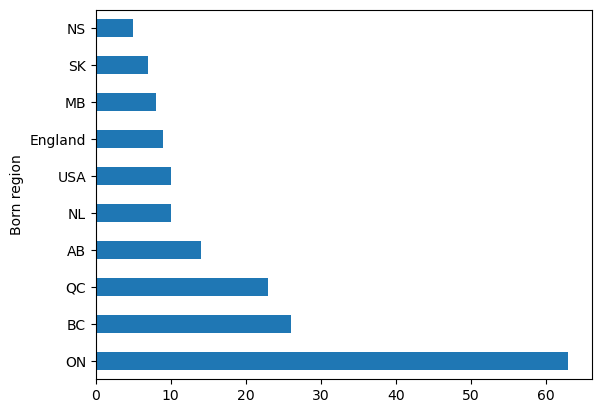

In [38]:
import matplotlib.pyplot as plt

born_counts.head(10).plot.barh()
plt.show()

This is a good start but there are some things we would like to fix:
- The biggest bar is at the **bottom**. `barh` draws the first value at the bottom, so we flip it.
- There is **no title**, and the numbers along the bottom have **no label**.

`.plot.barh()` gives back an object that we store in a variable called `ax` (short for "axes", matplotlib's word for one chart). We use `ax` to make these changes. 

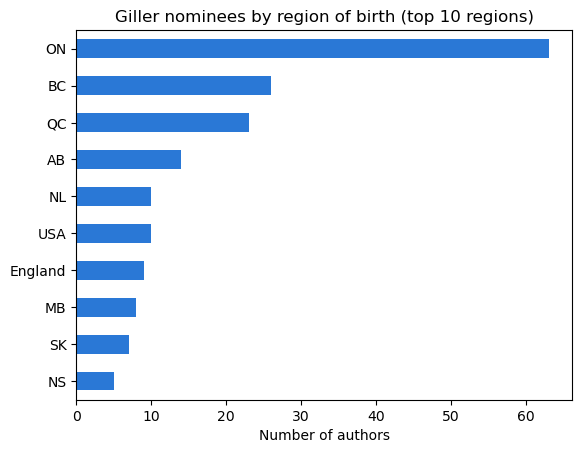

In [39]:
ax = born_counts.head(10).plot.barh(color="#2a78d6")

ax.invert_yaxis()   # put the biggest bar at the top
ax.set_title("Giller nominees by region of birth (top 10 regions)")
ax.set_xlabel("Number of authors")
ax.set_ylabel("")   # the region names speak for themselves
plt.show()

## 5. The same question for residences

Now we can ask where the nominees live, by changing just the column name. (We'll use orange for residences, so a reader can tell the two charts apart.)

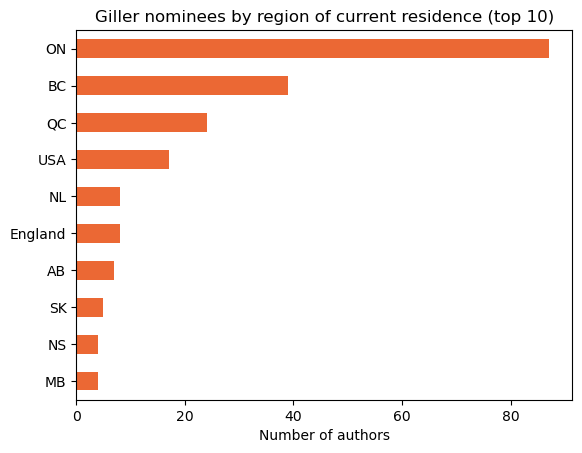

In [40]:
lives_counts = authors["Lives region"].value_counts()

ax = lives_counts.head(10).plot.barh(color="#eb6834")

ax.invert_yaxis()
ax.set_title("Giller nominees by region of current residence (top 10)")
ax.set_xlabel("Number of authors")
ax.set_ylabel("")
plt.show()

Two separate charts make us flip back and forth. We can put both counts side by side in one chart. `pd.DataFrame` builds a table from a dictionary, where each key becomes a column name and each value is a Series. The two Series are lined up by their region names. A region that appears in only one Series gets a missing value (`NaN`), so we use `.fillna(0)` to turn those into 0.

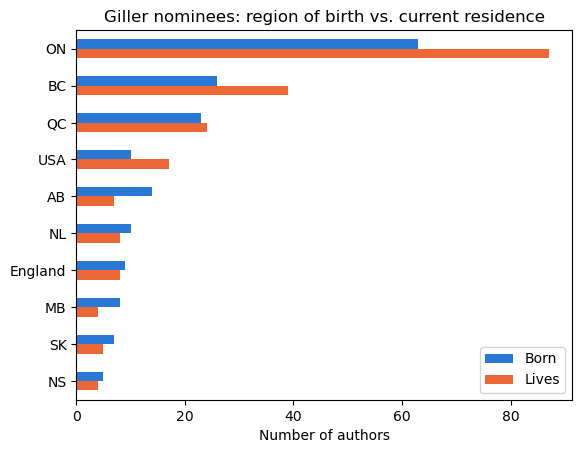

In [41]:
import pandas as pd

both = pd.DataFrame({"Born": born_counts, "Lives": lives_counts}).fillna(0)
both["Total"] = both["Born"] + both["Lives"]

# Keep the 10 regions with the most births plus residences combined
top = both.sort_values("Total", ascending=False).head(10)

ax = top[["Born", "Lives"]].plot.barh(color=["#2a78d6", "#eb6834"])

ax.invert_yaxis()
ax.set_title("Giller nominees: region of birth vs. current residence")
ax.set_xlabel("Number of authors")
ax.set_ylabel("")
plt.show()

In [42]:
born_other = authors[~authors["Born region"].isin(top.index)]
lives_other = authors[~authors["Lives region"].isin(top.index)]

print(len(born_other), "authors were born outside the 10 regions in the chart")
print(len(lives_other), "authors live outside the 10 regions in the chart")

43 authors were born outside the 10 regions in the chart
15 authors live outside the 10 regions in the chart


**Discussion:** Compare the two charts. Which regions have more nominees living there than were born there? Which have fewer? What might explain the difference?

## 6. Choosing rows: filtering

So far we have always used every row. Often we only want some of them: for example, only the nominees who were born outside Canada. In pandas, choosing rows is called **filtering**, and it takes two steps.

**Step 1:** Write a condition about a column. Just as `==` compares two values, here it compares *every* value in the column, and gives back a column of `True` and `False`.

You can think of this condition (or boolean expression) as a selector. When we use it like an index we get back only the rows that have True in our selector.

In [43]:
authors["Born in Canada"] == "Elsewhere"

0       True
1       True
2      False
3      False
4      False
       ...  
213     True
214    False
215    False
216    False
217    False
Name: Born in Canada, Length: 218, dtype: bool

**Step 2:** Now `born_elsewhere` is our boolean selector, and when we apply it to the `authors` dataframe, we get a new datafram with only the rows in which authors were born somewhere other than Canada.

In [44]:
born_elsewhere = authors["Born in Canada"] == "Elsewhere"
non_canadians = authors[born_elsewhere]

print(len(non_canadians), "authors born outside Canada")
non_canadians.head()

55 authors born outside Canada


,Author,Born,Born region,Born in Canada,Residence,Lives region,Lives in Canada,Nominations
0,Ann-Marie MacDonald,"CFB Baden-Soellingen, West Germany",West Germany,Elsewhere,"Toronto, ON",ON,Canada,2
1,Carol Shields,"Oak Park, IL, USA",USA,Elsewhere,"Victoria, BC",BC,Canada,2
5,Timothy Taylor,Venezuela,Venezuela,Elsewhere,"Vancouver, BC",BC,Canada,1
10,Claire Messud,"Greenwich, CT, USA",USA,Elsewhere,"Cambridge, MA, USA",USA,Elsewhere,2
14,Rawi Hage,"Beirut, Lebanon",Lebanon,Elsewhere,"Montreal, QC",QC,Canada,4


`non_canadians` is a new DataFrame with the same columns as `authors`, but only 55 rows. Everything we've learned works on it too. Where were these nominees born?

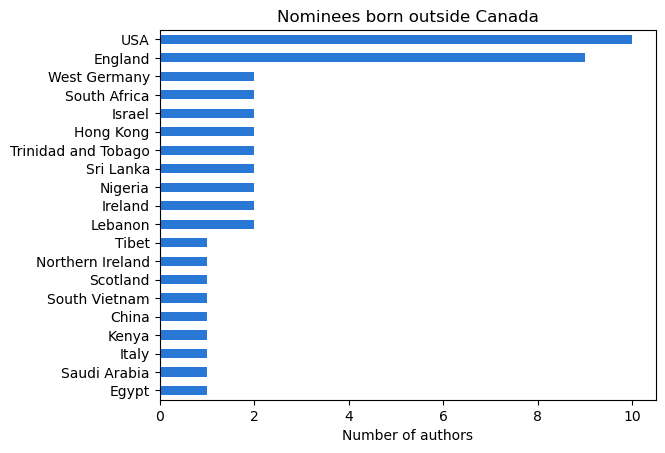

In [45]:
ax = non_canadians["Born region"].value_counts().head(20).plot.barh(color="#2a78d6")

ax.invert_yaxis()
ax.set_title("Nominees born outside Canada")
ax.set_xlabel("Number of authors")
ax.set_ylabel("")
plt.show()

Notice how we chained the steps together on one line: take the `"Born region"` column, count its values, keep the first 10, and plot them. You can always split a line like this into several steps with variables, as we did in section 3, if that's easier to read.

**Discussion:** The chart only shows the 20 most common places. How many different places are in the full list? (Try `len(born_elsewhere["Born region"].value_counts())`.) What does the chart hide about the variety of places Giller nominees come from?

Look closely at the bars after Lebanon: they are all tied at 1, so there are more that we aren't seeing.. Print `born_elsewhere["Born region"].value_counts()` and you'll find that other places (Ireland, for example) are tied at 2 as well but didn't make the top 10. pandas had to break the tie somehow. Would it be more fair to exclude every region that had only one nominee? f

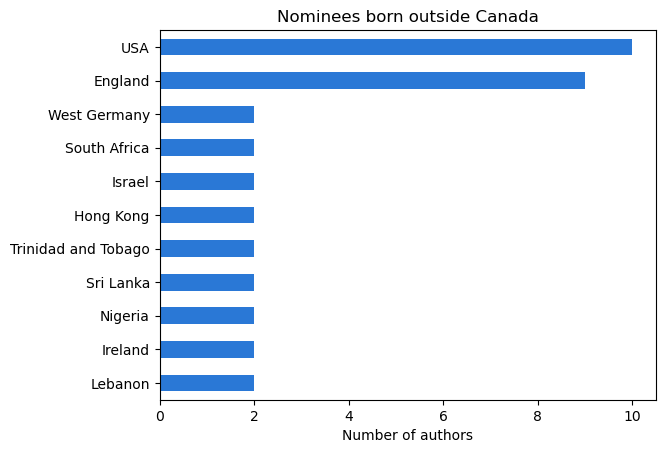

In [46]:
# Let's split up these operations and plot all regions (countries) that
# have at least 2 nominees.

# First get the counts for each region from our non_canadians dataframe
non_can_counts = non_canadians["Born region"].value_counts()

# The create a boolean selector for counts that are greater than two
# This will give us a column of Trues and Falses that we can apply to
# select only the rows we want.
non_can_at_least_two = non_can_counts >= 2

# We can finallyl get the Series that we want to plot.
plotdata = non_can_counts[non_can_at_least_two]

print()
ax = plotdata.plot.barh(color="#2a78d6")

ax.invert_yaxis()
ax.set_title("Nominees born outside Canada")
ax.set_xlabel("Number of authors")
ax.set_ylabel("")
plt.show()

## 7. Try it yourself

1. Use `.value_counts()` to find out how many nominees live outside Canada.
2. Make a filtered DataFrame of the nominees who **live** outside Canada, and draw a chart of where they live. Give it a title that states what you found.
3. The `Nominations` column holds numbers, so we can compare it with `>=` instead of `==`. Make a filtered DataFrame of the authors with 3 or more nominations, and print their names and nominations. (Hint: `filtered[["Author", "Nominations"]]` picks two columns at once.)
4. **Challenge:** Who was born in Canada but lives elsewhere? You'll need two conditions at once. In pandas, `&` plays the role of `and`, and each condition needs its own parentheses:
   ```python
   authors[(condition 1) & (condition 2)]
   ```

In [47]:
born_in_canada = authors["Born in Canada"] == "Canada"
lives_elsewhere = authors["Lives in Canada"] == "Elsewhere"

can_born = authors[born_in_canada & lives_elsewhere]

can_born


,Author,Born,Born region,Born in Canada,Residence,Lives region,Lives in Canada,Nominations
8,Alexi Zentner,"Kitchener, ON",ON,Canada,"Ithaca, NY, USA",USA,Elsewhere,1
16,Sarah Bernstein,"Montreal, QC",QC,Canada,Scotland,Scotland,Elsewhere,1
20,Patrick deWitt,"Sidney, BC",BC,Canada,"Portland, OR, USA",USA,Elsewhere,3
28,Antoine Wilson,"Montreal, QC",QC,Canada,"Los Angeles, CA, USA",USA,Elsewhere,1
53,Kim Fu,"Vancouver, BC",BC,Canada,"Seattle, WA, USA",USA,Elsewhere,1
58,"Pascale Quiviger, translated by Sheila Fischman","Montreal, QC",QC,Canada,"Nottingham, England",England,Elsewhere,1
64,Johanna Skibsrud,"Meadowville, NS",NS,Canada,"Tucson, AZ, USA",USA,Elsewhere,1
84,Marjorie Celona,"Victoria, BC",BC,Canada,"Cincinnati, OH, USA",USA,Elsewhere,1
90,Timothy Findley,"Toronto, ON",ON,Canada,"Brignoles, France",France,Elsewhere,2
95,Emily St. John Mandel,"Merville, BC",BC,Canada,"New York, NY, USA",USA,Elsewhere,1
